# Chapter 3 — Introduction to Neural Prediction: Forward Propagation
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

This chapter covers the first step of the **Predict → Compare → Learn** cycle: **Predict**.
Given inputs and a set of weights, how does a neural network produce an output? This process is
called **forward propagation** (or the *forward pass*).

All the networks below are implemented with plain NumPy. The weights are **hand-picked** — nothing
is learned yet; learning begins in Chapter 4.

> **Note on the examples.** To keep this notebook original, I use my own running example
> (a small drink stall predicting sales from the weather) rather than reusing the book's example
> scenarios. The concepts and the order of ideas follow the chapter.

**Roadmap**
1. A network with one input and one weight
2. Several inputs → one output (weighted sum / dot product)
3. One input → several outputs
4. Several inputs → several outputs (weight matrix)
5. Predicting for many examples at once (batches)
6. Stacked networks (hidden layers), and why they need something extra
7. NumPy cheat-sheet and shape rules

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=3, suppress=True)

## 1. The simplest network: one input, one weight

A neural network starts as a machine that **multiplies the input by a number**. That number is a **weight**:

$$\hat{y} = x \cdot w$$

- $x$ — the **input** (information we observe, e.g. today's temperature).
- $w$ — the **weight**, a *knob* measuring how strongly the output reacts to the input.
- $\hat{y}$ ("y-hat") — the **prediction**.

A positive weight means "more input → more output"; a negative weight means "more input → less output";
a weight near zero means the input is mostly ignored. The weights are where the network's
"knowledge" lives.

Example: a drink stall predicts how many cups it will sell from the temperature.

In [2]:
def predict_one(x, w):
    # a neural network with one input and one weight
    return x * w

temperature = 30.0      # input: degrees Celsius
weight = 2.5            # knob: extra cups sold per degree
prediction = predict_one(temperature, weight)
print(f"{temperature} °C  ->  predicted {prediction} cups")

30.0 °C  ->  predicted 75.0 cups


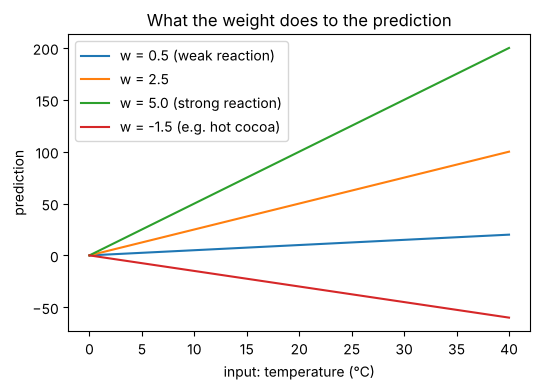

In [3]:
temps = np.linspace(0, 40, 50)
plt.figure(figsize=(5.5, 4))
for w, label in [(0.5, 'w = 0.5 (weak reaction)'), (2.5, 'w = 2.5'), (5.0, 'w = 5.0 (strong reaction)'),
                 (-1.5, 'w = -1.5 (e.g. hot cocoa)')]:
    plt.plot(temps, predict_one(temps, w), label=label)
plt.xlabel('input: temperature (°C)'); plt.ylabel('prediction')
plt.title('What the weight does to the prediction')
plt.legend(); plt.tight_layout()
plt.savefig('outputs/single_weight_lines.png', dpi=110)
plt.show()

**Reading the output.** Each weight defines a straight line through the origin; the weight *is* the
slope. Learning (Chapter 4) will mean choosing the slope whose line fits real data best.
Note the negative weight: a product like hot cocoa may sell *less* when it is warm.

## 2. Several inputs → one output: the weighted sum

Real predictions use several pieces of information. With one weight **per input**, the network
adds up every input multiplied by its own weight (a **weighted sum**):

$$\hat{y} = \sum_{i=1}^{n} x_i\,w_i = x_1 w_1 + x_2 w_2 + \dots + x_n w_n = \mathbf{x}\cdot\mathbf{w}$$

This is the **dot product** of the input vector and the weight vector.
Each term $x_i w_i$ is that input's *contribution* to the prediction.

Inputs for the stall: temperature (°C), is it a weekend (0/1), and the expected attendance of a nearby event
(in hundreds of people).

In [4]:
features = np.array([30.0, 1.0, 4.0])      # temperature, is_weekend, event attendance (hundreds)
weights  = np.array([2.0, 15.0, 0.8])      # hand-picked knobs

def weighted_sum(x, w):
    assert len(x) == len(w), "need exactly one weight per input"
    total = 0.0
    for xi, wi in zip(x, w):
        total += xi * wi
    return total

pred_loop = weighted_sum(features, weights)
pred_dot = np.dot(features, weights)
print("loop version   :", pred_loop)
print("np.dot version :", pred_dot)
print("same answer?   :", np.isclose(pred_loop, pred_dot))

loop version   : 78.2
np.dot version : 78.2
same answer?   : True


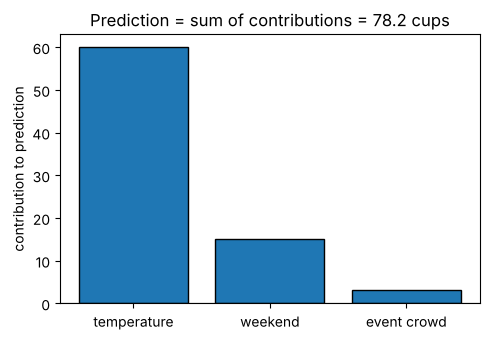

change when temperature rises by 1 °C: 2.0 (= weight[0])


In [5]:
contributions = features * weights          # element-wise product = each input's contribution
names = ['temperature', 'weekend', 'event crowd']

plt.figure(figsize=(5, 3.5))
plt.bar(names, contributions, edgecolor='k')
plt.axhline(0, color='k', lw=0.8)
plt.ylabel('contribution to prediction')
plt.title(f'Prediction = sum of contributions = {contributions.sum():.1f} cups')
plt.tight_layout()
plt.savefig('outputs/weighted_sum_contributions.png', dpi=110)
plt.show()

# Sensitivity: raising ONE input by 1 unit changes the prediction by exactly that input's weight
bumped = features.copy(); bumped[0] += 1
print("change when temperature rises by 1 °C:", np.dot(bumped, weights) - np.dot(features, weights), "(= weight[0])")

**Reading the output.** The bar chart decomposes the prediction into pieces, so we can see which
input matters most. The sensitivity check confirms the meaning of a weight in a weighted sum:
*how much the prediction changes when that input rises by one unit, holding the others fixed.*

### NumPy refresher: vectors
`+`, `*` between two arrays act **element by element**; a scalar is applied to every element
(*broadcasting*); `np.dot` multiplies element by element and then **sums**.

In [6]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 5.0, 6.0])

print("a + b          :", a + b)
print("a * b          :", a * b)
print("a * 2          :", a * 2)
print("a + 10         :", a + 10)
print("np.dot(a, b)   :", np.dot(a, b), "  == (a*b).sum() =", (a * b).sum())

a + b          : [5. 7. 9.]
a * b          : [ 4. 10. 18.]
a * 2          : [2. 4. 6.]
a + 10         : [11. 12. 13.]
np.dot(a, b)   : 32.0   == (a*b).sum() = 32.0


## 3. One input → several outputs

The reverse situation: a single input is used to predict several quantities. The simplest design gives
each output **its own weight**; the outputs are computed **independently** — they just happen to share the input.

Temperature → cups sold, bags of ice used, and staff-hours needed.

In [7]:
temperature = 30.0
weights_out = np.array([2.5, 0.4, 0.05])    # one weight per output

predictions = temperature * weights_out
for name, p in zip(['cups sold', 'bags of ice', 'staff-hours'], predictions):
    print(f"{name:12s}: {p:6.2f}")

cups sold   :  75.00
bags of ice :  12.00
staff-hours :   1.50


**Reading the output.** Three little one-weight networks are working side by side. Changing the
weight of "bags of ice" has no effect on the other two predictions.

## 4. Several inputs → several outputs: the weight matrix

Combine both ideas. **Each output has its own weighted sum over all inputs**, i.e. its own row of weights.
Stack those rows to get a **weight matrix** $W$ of shape *(number of outputs, number of inputs)*:

$$\hat{\mathbf{y}} = W\,\mathbf{x}\qquad
\hat y_j = \sum_{i} W_{ji}\,x_i$$

Row $j$ holds the weights feeding output $j$; column $i$ holds the weights that input $i$ sends out.
(Some texts store the matrix transposed and write $\mathbf{x}W$; it is the same computation,
only the bookkeeping differs.)

In [8]:
x = np.array([30.0, 1.0, 4.0])             # temperature, weekend, event crowd

W = np.array([[2.00, 15.0, 0.8],           # row 0: weights for 'cups sold'
              [0.40,  2.0, 0.1],           # row 1: weights for 'bags of ice'
              [0.05,  1.0, 0.2]])          # row 2: weights for 'staff-hours'

# explicit version: one weighted sum per output
pred_rows = np.array([weighted_sum(x, row) for row in W])
# matrix version
pred_matrix = W @ x

print("W shape :", W.shape, " x shape :", x.shape, " ->  prediction shape :", pred_matrix.shape)
print("row-by-row :", pred_rows)
print("W @ x      :", pred_matrix)
print("x @ W.T    :", x @ W.T, "(transposed convention, same numbers)")

W shape : (3, 3)  x shape : (3,)  ->  prediction shape : (3,)
row-by-row : [78.2 14.4  3.3]
W @ x      : [78.2 14.4  3.3]
x @ W.T    : [78.2 14.4  3.3] (transposed convention, same numbers)


## 5. Many examples at once (batches)

We rarely predict a single case. Stacking examples as the rows of a matrix $X$ of shape
*(examples, inputs)* lets one matrix product predict them all:

$$\hat Y = X\,W^{\top}\qquad \text{shape: }(N,\,n_{in})\cdot(n_{in},\,n_{out}) = (N,\,n_{out})$$

In [9]:
X = np.array([[30.0, 1.0,  4.0],
              [22.0, 0.0,  0.0],
              [35.0, 1.0, 10.0],
              [18.0, 0.0,  2.0]])          # four different days

Y_hat = X @ W.T
print("X shape:", X.shape, " Y_hat shape:", Y_hat.shape)
print("day | cups | ice bags | staff-hours")
for i, row in enumerate(Y_hat):
    print(f"  {i} | {row[0]:5.1f} | {row[1]:7.1f}  | {row[2]:6.2f}")

X shape: (4, 3)  Y_hat shape: (4, 3)
day | cups | ice bags | staff-hours
  0 |  78.2 |    14.4  |   3.30
  1 |  44.0 |     8.8  |   1.10
  2 |  93.0 |    17.0  |   4.75
  3 |  37.6 |     7.4  |   1.30


**Reading the output.** Row *i* of the result is the prediction for day *i*. Batch prediction is
how real systems run efficiently: one big matrix multiplication instead of many small loops.

## 6. Stacked networks: hidden layers

Nothing stops us feeding the output of one weight matrix into another. The values in the middle are the
**hidden layer**: not observed inputs, not final outputs, just intermediate quantities the network computes
along the way.

$$\mathbf{h} = W_1\,\mathbf{x}\qquad \hat{\mathbf{y}} = W_2\,\mathbf{h} = W_2 (W_1\,\mathbf{x})$$

With $W_1$ of shape (4, 3) and $W_2$ of shape (3, 4) we get a 3 → 4 → 3 network.

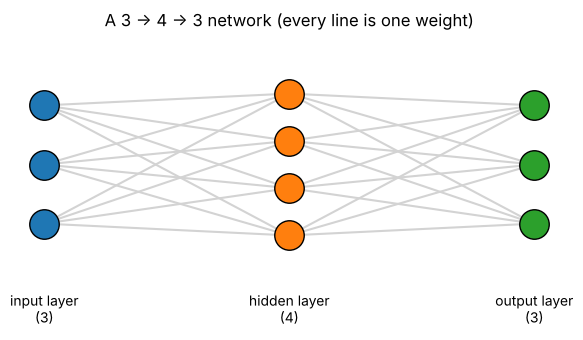

In [10]:
def draw_network(sizes, labels, title, filename):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ys = [np.linspace(0, 1, n + 2)[1:-1] for n in sizes]
    for layer in range(len(sizes) - 1):
        for y0 in ys[layer]:
            for y1 in ys[layer + 1]:
                ax.plot([layer, layer + 1], [y0, y1], color='lightgray', zorder=1)
    for layer, y_list in enumerate(ys):
        ax.scatter([layer] * len(y_list), y_list, s=450, zorder=2, edgecolor='k')
        ax.text(layer, -0.04, labels[layer], ha='center', va='top')
    ax.set_ylim(-0.2, 1.05); ax.axis('off'); ax.set_title(title)
    plt.tight_layout(); plt.savefig(filename, dpi=110); plt.show()

draw_network([3, 4, 3], ['input layer\n(3)', 'hidden layer\n(4)', 'output layer\n(3)'],
             'A 3 -> 4 -> 3 network (every line is one weight)', 'outputs/stacked_network.png')

In [11]:
rng = np.random.default_rng(4)
W1 = rng.normal(0, 0.5, size=(4, 3))        # input  -> hidden
W2 = rng.normal(0, 0.5, size=(3, 4))        # hidden -> output

def forward(x, layers):
    activation = x
    for weight_matrix in layers:
        activation = weight_matrix @ activation
    return activation

x = np.array([30.0, 1.0, 4.0])
hidden = W1 @ x
output = W2 @ hidden
print("hidden values :", hidden)
print("output        :", output)
print("same via forward():", np.allclose(output, forward(x, [W1, W2])))
print("number of weights:", W1.size + W2.size)

hidden values : [ -6.537   9.056 -12.494   6.896]
output        : [18.371 10.275 -3.652]
same via forward(): True
number of weights: 24


### A warning: stacking *linear* layers adds nothing by itself

Matrix multiplication is associative, so

$$W_2 (W_1 \mathbf{x}) = (W_2 W_1)\,\mathbf{x}.$$

The two-layer network is **exactly equivalent to a single layer** whose matrix is $W_2W_1$.

In [12]:
W_collapsed = W2 @ W1                       # shape (3, 3)
print("collapsed shape:", W_collapsed.shape)
print("one layer  :", W_collapsed @ x)
print("two layers :", W2 @ (W1 @ x))
print("identical? :", np.allclose(W_collapsed @ x, W2 @ (W1 @ x)))

collapsed shape: (3, 3)
one layer  : [18.371 10.275 -3.652]
two layers : [18.371 10.275 -3.652]
identical? : True


**Reading the output.** The two answers are identical, so a hidden layer made only of weighted sums
cannot represent anything a single layer could not. Hidden layers become powerful only when a
**non-linear function** is inserted between the layers — the key ingredient introduced in
Chapter 6.

## 7. Shape rules (the most common source of bugs)

| Operation | Shapes | Result |
|---|---|---|
| vector · vector | (n,) · (n,) | scalar |
| matrix @ vector | (m, n) @ (n,) | (m,) |
| matrix @ matrix | (m, n) @ (n, k) | (m, k) |
| batch of examples | (N, n_in) @ (n_in, n_out) | (N, n_out) |

The *inner* dimensions must match; the outer ones form the result.

## Summary

- **Forward propagation** = turning inputs into predictions by repeated weighted sums.
- A **weight** is a knob measuring how strongly an input affects an output; the weights are the network's knowledge.
- One neuron computes a **dot product**; a layer of neurons is a **matrix–vector product**; a batch is a **matrix–matrix product**.
- Stacking purely linear layers collapses into one linear layer — so something more is needed (Chapter 6).
- So far the weights were invented by hand. **Chapter 4** shows how to learn them from the error.